# 3. Portfolio risk

1-day 99% VaR and CVaR in CAD for a seven-stock Canadian and US portfolio, by historical simulation, Gaussian Monte Carlo and Student-t Monte Carlo, with a rolling backtest and stress scenarios.

The notebook uses `data/prices.csv` if it exists (`uv run --extra data python scripts/download_data.py`) and falls back to clearly labelled synthetic data otherwise.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mc_risk.risk import (
    DEFAULT_WEIGHTS, PORTFOLIO, cad_returns, fit_student_t_dof, fx_shock, gaussian_mc_var,
    historical_replay, historical_var, load_prices, rolling_backtest, student_t_mc_var,
    summarise_backtest, synthetic_prices,
)

path = Path('../data/prices.csv')
prices = load_prices(path) if path.exists() else synthetic_prices(seed=0)
print('data source:', 'real (Yahoo Finance)' if path.exists() else 'SYNTHETIC - not market results')
rets = cad_returns(prices)
w = np.array([DEFAULT_WEIGHTS[t] for t in PORTFOLIO])
print(f'{len(rets)} return days, {rets.index[0].date()} to {rets.index[-1].date()}')

data source: real (Yahoo Finance)
1760 return days, 2020-01-03 to 2026-11-13


## VaR and CVaR on the latest 500 days

In [2]:
x = rets[PORTFOLIO].to_numpy()[-500:]
nu = fit_student_t_dof(x)
res = [historical_var(x, w), gaussian_mc_var(x, w, seed=0), student_t_mc_var(x, w, seed=0, dof=nu)]
print(f'fitted Student-t degrees of freedom: {nu:.2f}')
pd.DataFrame({'VaR %': [100 * r.var for r in res], 'CVaR %': [100 * r.cvar for r in res],
              'VaR CAD (1m portfolio)': [1e6 * r.var for r in res]}, index=[r.method for r in res]).round(2)

fitted Student-t degrees of freedom: 4.59


,VaR %,CVaR %,VaR CAD (1m portfolio)
historical,2.54,4.11,25449.32
gaussian-mc,2.44,2.81,24418.78
student-t-mc,2.76,3.76,27563.87


The Gaussian model has the lowest CVaR: its tail is too thin. The fitted Student-t has heavy tails and sits closer to the historical tail.

## Rolling backtest

Each day's VaR uses only the 500 days before it.

In [3]:
bts = {m: rolling_backtest(rets[PORTFOLIO], w, m, window=500, n_sims=10_000, seed=0)
       for m in ('historical', 'gaussian-mc', 'student-t-mc')}
pd.DataFrame({m: summarise_backtest(bt) for m, bt in bts.items()}).T.round(3)

,days,exceedances,expected,rate,kupiec_p,independence_p,cond_coverage_p,mean_exceed_ratio
historical,1260.0,18.0,12.6,0.014,0.151,0.256,0.187,1.355
gaussian-mc,1260.0,26.0,12.6,0.021,0.001,0.113,0.001,1.336
student-t-mc,1260.0,16.0,12.6,0.013,0.355,0.196,0.282,1.346


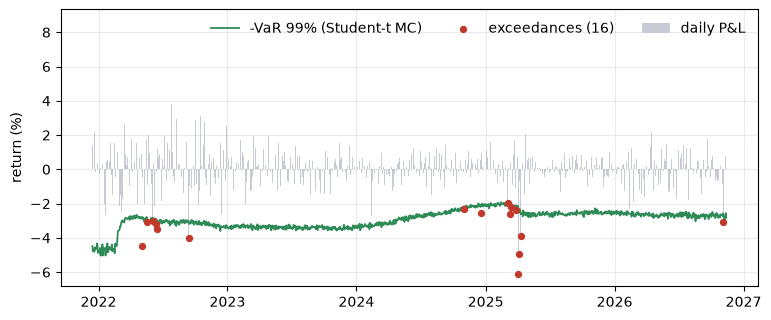

In [4]:
bt = bts['student-t-mc']
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(bt.index, -100 * bt['loss'], width=1.0, color='#c7ccd4', label='daily P&L')
ax.plot(bt.index, -100 * bt['var'], color='#2e8b57', lw=1.3, label='-VaR 99% (Student-t MC)')
hits = bt[bt['exceed']]
ax.scatter(hits.index, -100 * hits['loss'], color='#c0392b', s=18, zorder=3, label=f'exceedances ({len(hits)})')
ax.set_ylabel('return (%)'); ax.legend(frameon=False, ncol=3); ax.grid(alpha=0.25)
plt.show()

## Stress scenarios

In [5]:
rows = {}
for label, start, end in (('COVID crash replay', '2020-02-20', '2020-03-23'), ('2022 sell-off replay', '2022-01-03', '2022-06-16')):
    rows[label] = historical_replay(rets, DEFAULT_WEIGHTS, start, end)['total_return']
rows['CAD -10% against USD'] = fx_shock(DEFAULT_WEIGHTS, -0.10)
rows['CAD +10% against USD'] = fx_shock(DEFAULT_WEIGHTS, 0.10)
pd.Series(rows, name='portfolio return').map('{:+.1%}'.format).to_frame()

,portfolio return
COVID crash replay,-28.9%
2022 sell-off replay,-25.1%
CAD -10% against USD,+5.6%
CAD +10% against USD,-4.5%


A weaker Canadian dollar is a gain for this portfolio because half of it is in US stocks. The currency loss scenario is a CAD rally.